Данные: [Book Recommendation Dataset на Kaggle](https://www.kaggle.com/datasets/arashnic/book-recommendation-dataset).

In [ ]:
import gc
import re
import unicodedata
import warnings
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import LabelEncoder
from implicit.als import AlternatingLeastSquares
from tqdm.auto import tqdm
from catboost import CatBoostRanker, Pool


warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

POSITIVE_RATING_THRESHOLD = 7
NEGATIVE_RATING_MAX = 6

TOPK_PER_MODEL = 100
FINAL_TOP_K = 20

ALS_FACTORS = 64
ALS_ITERATIONS = 12
ALS_REGULARIZATION = 0.05
ALS_ALPHA = 15.0
ALS_THREADS = 4
FACTOR_SCORE_BATCH_USERS = 64

MAX_RANKER_USERS = 6_000
MAX_EVAL_USERS = 2_500
RANKER_ITERATIONS = 700
RANKER_DEPTH = 7
RANKER_LEARNING_RATE = 0.03
RANKER_EARLY_STOPPING = 80

INFERENCE_BATCH_SIZE = 1_000
INFER_ALL_USERS = True

DATA_SEARCH_ROOTS = [Path("."), Path("./data")]

e:\Предметы\Магистратура\Семестр 3\Рекомендательные системы\final-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Загрузка данных

In [2]:
def find_dataset_file(filename: str) -> Path:
    candidates = []
    for root in DATA_SEARCH_ROOTS:
        if root.exists():
            direct = root / filename
            if direct.is_file():
                candidates.append(direct)
            try:
                candidates.extend(p for p in root.rglob(filename) if p.is_file())
            except (PermissionError, OSError):
                pass
    return sorted(set(candidates), key=lambda p: (len(p.parts), str(p)))[0]

books_path = find_dataset_file("Books.csv")
ratings_path = find_dataset_file("Ratings.csv")
users_path = find_dataset_file("Users.csv")
print("Книги:", books_path)
print("Рейтинги:", ratings_path)
print("Пользователи:", users_path)

books_raw = pd.read_csv(books_path, dtype={"ISBN": "string"}, encoding="latin-1", low_memory=False)
ratings_raw = pd.read_csv(ratings_path, dtype={"ISBN": "string"}, encoding="latin-1", low_memory=False)
users_raw = pd.read_csv(users_path, encoding="latin-1", low_memory=False)

print("Размеры исходных таблиц:", {"books": books_raw.shape, "ratings": ratings_raw.shape, "users": users_raw.shape})
display(books_raw.head(3))
display(ratings_raw.head(3))
display(users_raw.head(3))

Книги: data\Books.csv
Рейтинги: data\Ratings.csv
Пользователи: data\Users.csv
Размеры исходных таблиц: {'books': (271360, 8), 'ratings': (1149780, 3), 'users': (278858, 3)}


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN


## Качество данных


Таблица «Books»: размер=(271360, 8)


,dtype,missing_count,missing_pct,n_unique
ISBN,string,0,0.0,271360
Book-Title,str,0,0.0,242135
Book-Author,str,2,0.0,102022
Year-Of-Publication,str,0,0.0,118
Publisher,str,2,0.0,16807
Image-URL-S,str,0,0.0,271044
Image-URL-M,str,0,0.0,271044
Image-URL-L,str,3,0.0,271041


Строк с дублирующимися ключами: 0

Таблица «Ratings»: размер=(1149780, 3)


,dtype,missing_count,missing_pct,n_unique
User-ID,int64,0,0.0,105283
ISBN,string,0,0.0,340556
Book-Rating,int64,0,0.0,11


Строк с дублирующимися ключами: 0

Таблица «Users»: размер=(278858, 3)


,dtype,missing_count,missing_pct,n_unique
User-ID,int64,0,0.00,278858
Location,str,0,0.00,57339
Age,float64,110762,39.72,165


Строк с дублирующимися ключами: 0

Названия столбцов:
Книги: ['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']
Рейтинги: ['User-ID', 'ISBN', 'Book-Rating']
Пользователи: ['User-ID', 'Location', 'Age']


,count
rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


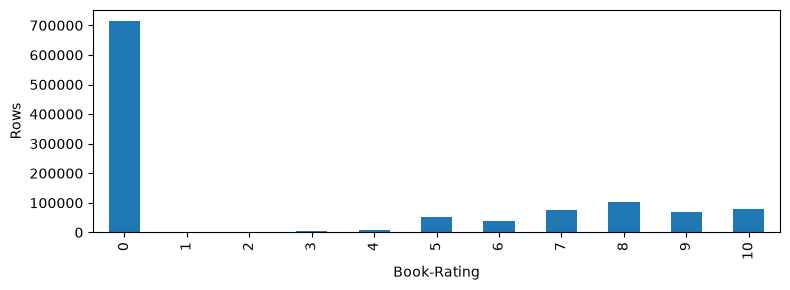

In [3]:
def audit_table(name: str, df: pd.DataFrame, key_cols: Optional[List[str]] = None) -> pd.DataFrame:
    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (100 * df.isna().mean()).round(2),
        "n_unique": df.nunique(dropna=True),
    })
    print(f"\nТаблица «{name}»: размер={df.shape}")
    display(report)
    if key_cols:
        print("Строк с дублирующимися ключами:", int(df.duplicated(key_cols).sum()))
    return report

books_audit = audit_table("Books", books_raw, ["ISBN"] if "ISBN" in books_raw else None)
ratings_audit = audit_table("Ratings", ratings_raw, ["User-ID", "ISBN"] if {"User-ID", "ISBN"}.issubset(ratings_raw.columns) else None)
users_audit = audit_table("Users", users_raw, ["User-ID"] if "User-ID" in users_raw else None)

print("\nНазвания столбцов:")
print("Книги:", books_raw.columns.tolist())
print("Рейтинги:", ratings_raw.columns.tolist())
print("Пользователи:", users_raw.columns.tolist())

if "Book-Rating" in ratings_raw:
    display(ratings_raw["Book-Rating"].value_counts(dropna=False).sort_index().rename_axis("rating").to_frame("count"))
    ratings_raw["Book-Rating"].value_counts(dropna=False).sort_index().plot(kind="bar", figsize=(8, 3))
    plt.xlabel("Book-Rating")
    plt.ylabel("Rows")
    plt.tight_layout()
    plt.show()

## EDA

In [ ]:
REQUIRED_BOOKS   = {"ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"}
REQUIRED_RATINGS = {"User-ID", "ISBN", "Book-Rating"}
REQUIRED_USERS   = {"User-ID", "Location", "Age"}

VALID_YEAR_RANGE = (1450, 2026)
VALID_AGE_RANGE  = (5, 100)
VALID_RATING_RANGE = (0, 10)

NULL_LIKE = {"", "NULL", "nan"}

AGE_BINS   = [0, 12, 17, 29, 44, 59, 100]
AGE_LABELS = ["child", "teen", "young_adult", "adult", "middle_age", "senior"]


def check_columns(name: str, frame: pd.DataFrame, required: set[str]) -> None:
    """Проверяет, что во входной таблице есть все обязательные колонки."""
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"В {name} отсутствуют обязательные столбцы: {sorted(missing)}")


def normalize_work_component(value: Any) -> str:
    """Нормализует название/автора"""
    if pd.isna(value):
        return ""
    text = unicodedata.normalize("NFKC", str(value)).casefold()
    text = text.replace("&", " and ")
    text = re.sub(r"[^\w]+", " ", text, flags=re.UNICODE)
    return " ".join(text.split()).strip()


def clean_text_column(series: pd.Series) -> pd.Series:
    """Замена NULL значений на 'Unknown'"""
    s = series.astype("string").str.strip()
    s = s.replace({v: pd.NA for v in NULL_LIKE})
    return s.fillna("Unknown").astype(str)


for name, frame, required in [
    ("Books",   books_raw,   REQUIRED_BOOKS),
    ("Ratings", ratings_raw, REQUIRED_RATINGS),
    ("Users",   users_raw,   REQUIRED_USERS),
]:
    check_columns(name, frame, required)


books = books_raw.copy()

books["ISBN"] = books["ISBN"].astype("string").str.strip()
books = books[
    books["ISBN"].notna()
    & books["ISBN"].ne("")
    & books["ISBN"].ne("ISBN")
].copy()

for col in ["Book-Title", "Book-Author", "Publisher"]:
    books[col] = clean_text_column(books[col])

books["Year-Of-Publication"] = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
in_range = books["Year-Of-Publication"].between(*VALID_YEAR_RANGE)
books.loc[~in_range, "Year-Of-Publication"] = np.nan
books["Year-Of-Publication"] = books["Year-Of-Publication"].astype(float)

books = books.drop_duplicates("ISBN", keep="first").reset_index(drop=True)
books["ISBN"] = books["ISBN"].astype(str)



title_norm  = books["Book-Title"].map(normalize_work_component)
author_norm = books["Book-Author"].map(normalize_work_component)

title_unknown  = title_norm.isin(["", "unknown"])
author_unknown = author_norm.isin(["", "unknown"])

books["_work_key"] = "title::" + title_norm

known_title_author = (~title_unknown) & (~author_unknown)
books.loc[known_title_author, "_work_key"] = (
    "title_author::"
    + title_norm.loc[known_title_author]
    + "::"
    + author_norm.loc[known_title_author]
)

books.loc[title_unknown, "_work_key"] = "isbn::" + books.loc[title_unknown, "ISBN"]

isbn_to_work_key = (
    books.drop_duplicates("ISBN")
         .set_index("ISBN")["_work_key"]
         .astype(str)
         .to_dict()
)

print("Уникальных изданий ISBN:", books["ISBN"].nunique())
print("Примерное число произведений после нормализации названия и автора:",
      books["_work_key"].nunique())


ratings = ratings_raw.copy()

ratings["ISBN"]        = ratings["ISBN"].astype("string").str.strip()
ratings["User-ID"]     = pd.to_numeric(ratings["User-ID"], errors="coerce")
ratings["Book-Rating"] = pd.to_numeric(ratings["Book-Rating"], errors="coerce")

ratings = ratings.dropna(subset=["User-ID", "ISBN", "Book-Rating"])
ratings["User-ID"] = ratings["User-ID"].astype("int64")

ratings = ratings[
    ratings["ISBN"].ne("")
    & ratings["Book-Rating"].between(*VALID_RATING_RANGE)
].copy()
ratings["Book-Rating"] = ratings["Book-Rating"].astype("int8")

ratings = ratings.groupby(["User-ID", "ISBN"], as_index=False, sort=False)["Book-Rating"].max()
ratings["ISBN"] = ratings["ISBN"].astype(str)

ratings = ratings[ratings["ISBN"].isin(set(books["ISBN"]))].reset_index(drop=True)

ratings["_row_id"] = np.arange(len(ratings), dtype=np.int64)



users = users_raw.copy()

users["User-ID"] = pd.to_numeric(users["User-ID"], errors="coerce")
users = users.dropna(subset=["User-ID"]).copy()
users["User-ID"] = users["User-ID"].astype("int64")
users = users.drop_duplicates("User-ID", keep="first")

users["Age"] = pd.to_numeric(users["Age"], errors="coerce")
users.loc[~users["Age"].between(*VALID_AGE_RANGE), "Age"] = np.nan

users["Location"] = users["Location"].astype("string").fillna("Unknown").str.strip()
users["Country"] = (
    users["Location"].str.split(",").str[-1]
         .str.strip()
         .str.lower()
         .replace({"": "unknown", "nan": "unknown", "<na>": "unknown"})
         .fillna("unknown")
)

users["AgeGroup"] = (
    pd.cut(users["Age"], bins=AGE_BINS, labels=AGE_LABELS)
      .astype("string")
      .fillna("unknown")
)

users = users[["User-ID", "Age", "Country", "AgeGroup"]].reset_index(drop=True)


print("Размеры очищенных таблиц:",
      {"books": books.shape, "ratings": ratings.shape, "users": users.shape})
print("Диапазон рейтингов:",
      ratings["Book-Rating"].min(), "..", ratings["Book-Rating"].max())
print("Дубликатов пар пользователь–книга после очистки:",
      int(ratings.duplicated(["User-ID", "ISBN"]).sum()))
print("Рейтингов без метаданных книги:",
      int((~ratings["ISBN"].isin(books["ISBN"])).sum()))

display(books.head(3))
display(ratings.head(3))
display(users.head(3))

Уникальных изданий ISBN: 271359
Примерное число произведений после нормализации названия и автора: 245668
Размеры очищенных таблиц: {'books': (271359, 9), 'ratings': (1031139, 4), 'users': (278858, 4)}
Диапазон рейтингов: 0 .. 10
Дубликатов пар пользователь–книга после очистки: 0
Рейтингов без метаданных книги: 0


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,_work_key
0,0195153448,Classical Mythology,Mark P. O. Morford,2002.0,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,title_author::classical mythology::mark p o mo...
1,0002005018,Clara Callan,Richard Bruce Wright,2001.0,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,title_author::clara callan::richard bruce wright
2,0060973129,Decision in Normandy,Carlo D'Este,1991.0,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,title_author::decision in normandy::carlo d este


,User-ID,ISBN,Book-Rating,_row_id
0,276725,034545104X,0,0
1,276726,0155061224,5,1
2,276727,0446520802,0,2


,User-ID,Age,Country,AgeGroup
0,1,NaN,usa,unknown
1,2,18.0,usa,young_adult
2,3,NaN,russia,unknown


## Таргит

Users in Рейтинги: 92,106
Книг хотя бы с одним взаимодействием: 270,151
Строк взаимодействий пользователь–книга: 1,031,139
Положительных/неявных целевых взаимодействий: 937,505 (90.9%)
Явные оценки от 1 до 6: 93,634
Плотность матрицы по наблюдаемым пользователям и книгам: 0.004144%


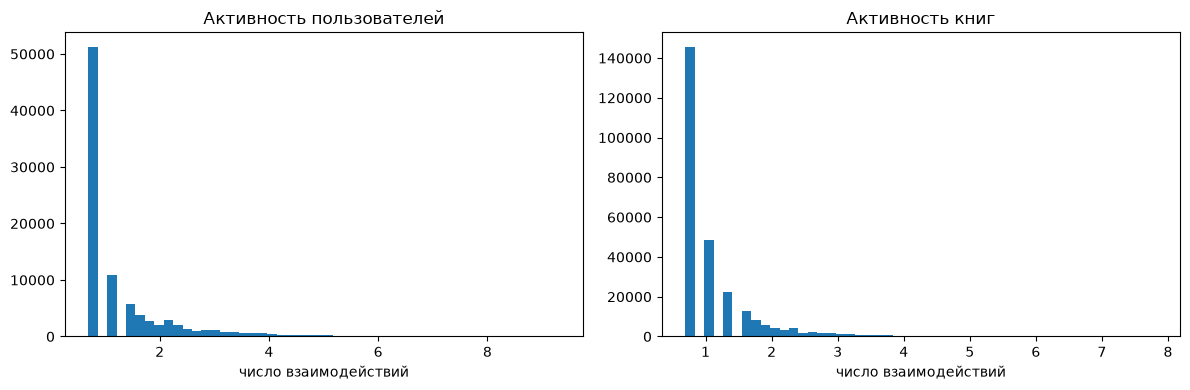

In [5]:
def positive_mask(frame: pd.DataFrame) -> pd.Series:
    return (frame["Book-Rating"].eq(0) | frame["Book-Rating"].ge(POSITIVE_RATING_THRESHOLD))

ratings["is_positive"] = positive_mask(ratings)
positive_ratings = ratings[ratings["is_positive"]].copy()

n_users_interacted = ratings["User-ID"].nunique()
n_items_interacted = ratings["ISBN"].nunique()
interaction_density = len(ratings) / max(1, n_users_interacted * n_items_interacted)
print(f"Users in Рейтинги: {n_users_interacted:,}")
print(f"Книг хотя бы с одним взаимодействием: {n_items_interacted:,}")
print(f"Строк взаимодействий пользователь–книга: {len(ratings):,}")
print(f"Положительных/неявных целевых взаимодействий: {len(positive_ratings):,} ({len(positive_ratings)/len(ratings):.1%})")
print(f"Явные оценки от 1 до 6: {(ratings['Book-Rating'].between(1, 6)).sum():,}")
print(f"Плотность матрицы по наблюдаемым пользователям и книгам: {interaction_density:.6%}")

user_activity = ratings.groupby("User-ID").size()
item_activity = ratings.groupby("ISBN").size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(user_activity), bins=50)
axes[0].set_title("Активность пользователей")
axes[0].set_xlabel("число взаимодействий")
axes[1].hist(np.log1p(item_activity), bins=50)
axes[1].set_title("Активность книг")
axes[1].set_xlabel("число взаимодействий")
plt.tight_layout()
plt.show()

## Подготовка данных для обучения

In [7]:
rating_work = ratings[["_row_id", "User-ID", "ISBN", "Book-Rating"]].copy()
rating_work["_work_key"] = rating_work["ISBN"].map(isbn_to_work_key).fillna(
    rating_work["ISBN"].map(lambda x: f"isbn::{x}")
)

positive_rows = rating_work.loc[
    positive_mask(rating_work),
    ["_row_id", "User-ID", "ISBN", "Book-Rating", "_work_key"],
]


rng = np.random.default_rng(SEED)
ranker_work_pairs = set()
test_work_pairs = set()
users_with_holdout = 0

for uid, group in positive_rows.groupby("User-ID", sort=False):
    work_keys = group["_work_key"].drop_duplicates().to_numpy(copy=True)

    if len(work_keys) < 3:
        continue

    rng.shuffle(work_keys)

    n_test = max(1, int(round(0.20 * len(work_keys))))
    n_ranker = max(1, int(round(0.20 * len(work_keys))))

    while n_test + n_ranker > len(work_keys) - 1:
        if n_test >= n_ranker and n_test > 1:
            n_test -= 1
        elif n_ranker > 1:
            n_ranker -= 1
        else:
            break

    test_work_pairs.update(
        (int(uid), str(work_key)) for work_key in work_keys[:n_test]
    )
    ranker_work_pairs.update(
        (int(uid), str(work_key))
        for work_key in work_keys[n_test:n_test + n_ranker]
    )
    users_with_holdout += 1

reserved_work_pairs = test_work_pairs | ranker_work_pairs

row_pairs = list(zip(
    rating_work["User-ID"].astype(int),
    rating_work["_work_key"].astype(str),
))

reserved_mask = pd.Series(
    [pair in reserved_work_pairs for pair in row_pairs],
    index=rating_work.index,
)
test_mask = pd.Series(
    [pair in test_work_pairs for pair in row_pairs],
    index=rating_work.index,
)
ranker_mask = pd.Series(
    [pair in ranker_work_pairs for pair in row_pairs],
    index=rating_work.index,
)



base_train = ratings.loc[~reserved_mask].drop(columns=["_row_id"]).copy()

ranker_target = ratings.loc[
    ranker_mask & positive_mask(ratings)
].drop(columns=["_row_id"]).copy()

test_target = ratings.loc[
    test_mask & positive_mask(ratings)
].drop(columns=["_row_id"]).copy()

model_train = ratings.loc[~test_mask].drop(columns=["_row_id"]).copy()

print("Пользователей, подходящих для отложенной выборки:", f"{users_with_holdout:,}")
print(
    "Отложенных пар (пользователь, произведение) — ранкер:",
    f"{len(ranker_work_pairs):,}",
    "| test:",
    f"{len(test_work_pairs):,}",
)
print(
    "Размеры выборок: base_train:", base_train.shape,
    "ranker_target:", ranker_target.shape,
    "test_target:", test_target.shape,
)
print("Размер model_train:", model_train.shape)
print(
    "Пересечение произведений между ранкерной и тестовой выборками:",
    len(ranker_work_pairs & test_work_pairs),
)
print("Число обучающих положительных событий на пользователя:")
base_pos_counts = base_train[positive_mask(base_train)].groupby("User-ID").size()
heldout_users = test_target["User-ID"].unique()
print(base_pos_counts.reindex(heldout_users).fillna(0).describe())

Пользователей, подходящих для отложенной выборки: 26,895
Отложенных пар (пользователь, произведение) — ранкер: 175,591 | test: 175,591
Размеры выборок: base_train: (678243, 4) ranker_target: (176365, 4) test_target: (176412, 4)
Размер model_train: (854665, 4)
Пересечение произведений между ранкерной и тестовой выборками: 0
Число обучающих положительных событий на пользователя:
count    26895.000000
mean        19.239227
std         91.489246
min          1.000000
25%          2.000000
50%          4.000000
75%         10.000000
max       5536.000000
dtype: float64


## Метрики

In [8]:
def build_seen_map(history: pd.DataFrame) -> Dict[int, set]:
    """Возвращает ISBN, уже присутствующие в истории каждого пользователя (на уровне издания)"""
    if history.empty:
        return {}
    
    return history.groupby("User-ID")["ISBN"].agg(lambda s: set(s.astype(str))).to_dict()


def build_seen_work_map(history: pd.DataFrame) -> Dict[int, set]:
    """Возвращает нормализованные произведения, уже присутствующие в истории каждого пользователя, по всем изданиям"""
    if history.empty:
        return {}
    tmp = history[["User-ID", "ISBN"]].copy()
    tmp["ISBN"] = tmp["ISBN"].astype(str)
    tmp["_work_key"] = tmp["ISBN"].map(isbn_to_work_key).fillna(tmp["ISBN"].map(lambda x: f"isbn::{x}"))

    return tmp.groupby("User-ID")["_work_key"].agg(lambda s: set(s.astype(str))).to_dict()


def dedupe_recommendations_by_work(
    recommendations: Dict[int, List[Tuple[str, float]]],
    seen_isbns: Dict[int, set],
    seen_works: Dict[int, set],
    k: int,
) -> Dict[int, List[Tuple[str, float]]]:
    """Удаляет издания уже просмотренных произведений и оставляет только издание с наивысшим рангом для каждого произведения"""
    result: Dict[int, List[Tuple[str, float]]] = {}
    for uid, pairs in recommendations.items():
        uid = int(uid)
        already_seen_isbns = seen_isbns.get(uid, set())
        already_seen_works = seen_works.get(uid, set())
        used_works = set()
        kept = []

        # Входной порядок — по убыванию оценки модели / ранга рекомендации
        for isbn, score in pairs:
            isbn = str(isbn)
            work_key = isbn_to_work_key.get(isbn, f"isbn::{isbn}")
            if isbn in already_seen_isbns or work_key in already_seen_works or work_key in used_works:
                continue

            kept.append((isbn, float(score)))
            used_works.add(work_key)
            if len(kept) >= k:
                break
        result[uid] = kept

    return result


def build_ground_truth(target: pd.DataFrame) -> Dict[int, set]:
    """Ответы на уровне изданий"""
    if target.empty:
        return {}
    return target.groupby("User-ID")["ISBN"].agg(lambda s: set(s.astype(str))).to_dict()


def build_work_ground_truth(target: pd.DataFrame) -> Dict[int, set]:
    """Ответы с ключом по нормализованному произведению, поэтому альтернативные издания считаются одной и той же книгой"""
    if target.empty:
        return {}
    tmp = target[["User-ID", "ISBN"]].copy()
    tmp["ISBN"] = tmp["ISBN"].astype(str)
    tmp["_work_key"] = tmp["ISBN"].map(isbn_to_work_key).fillna(tmp["ISBN"].map(lambda x: f"isbn::{x}"))
    return tmp.groupby("User-ID")["_work_key"].agg(lambda s: set(s.astype(str))).to_dict()


def safe_list_recommendations(pairs: Iterable[Tuple[str, float]], seen: set, k: int) -> List[Tuple[str, float]]:
    out, added = [], set()
    for item, score in pairs:
        item = str(item)
        if item in seen or item in added:
            continue
        out.append((item, float(score)))
        added.add(item)
        if len(out) >= k:
            break
    return out


def evaluate_recommendations(
    recommendations: Dict[int, List[Tuple[str, float]]],
    ground_truth: Dict[int, set],
    user_ids: Iterable[int],
    k: int = 10,
    match_by_work: bool = False,
) -> Dict[str, float]:
    """Вычисляет Recall/NDCG/HitRate/MAP"""
    recalls, ndcgs, hits, maps = [], [], [], []

    for uid in user_ids:
        gt = set(ground_truth.get(int(uid), set()))
        if not gt:
            continue
        recs = recommendations.get(int(uid), [])[:k]
        raw_items = [str(x[0]) for x in recs]
        rec_items = [isbn_to_work_key.get(item, f"isbn::{item}") for item in raw_items] if match_by_work else raw_items
        # Повторяющееся произведение не должно добавлять более одного попадания в метрику.
        if match_by_work:
            unique_items, seen_work = [], set()
            for item in rec_items:
                if item not in seen_work:
                    unique_items.append(item)
                    seen_work.add(item)
            rec_items = unique_items

        rel = np.asarray([1.0 if item in gt else 0.0 for item in rec_items], dtype=float)
        n_hits = int(rel.sum())
        recalls.append(n_hits / len(gt))
        hits.append(float(n_hits > 0))

        discounts = 1.0 / np.log2(np.arange(2, len(rel) + 2))
        dcg = float(np.sum(rel * discounts))

        ideal_len = min(len(gt), k)
        idcg = float(np.sum(1.0 / np.log2(np.arange(2, ideal_len + 2)))) if ideal_len else 0.0

        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)
        precision_sum = 0.0
        found = 0

        for rank, item in enumerate(rec_items, start=1):
            if item in gt:
                found += 1
                precision_sum += found / rank
        maps.append(precision_sum / min(len(gt), k))
    if not recalls:
        return {f"Recall@{k}": 0.0, f"NDCG@{k}": 0.0, f"HitRate@{k}": 0.0, f"MAP@{k}": 0.0}
    
    return {
        f"Recall@{k}": float(np.mean(recalls)),
        f"NDCG@{k}": float(np.mean(ndcgs)),
        f"HitRate@{k}": float(np.mean(hits)),
        f"MAP@{k}": float(np.mean(maps)),
    }


def evaluate_candidate_recall(
    candidates: pd.DataFrame,
    ground_truth: Dict[int, set],
    user_ids: Iterable[int],
    match_by_work: bool = False,
) -> float:
    if candidates.empty:
        return 0.0
    tmp = candidates[["User-ID", "ISBN"]].copy()
    tmp["ISBN"] = tmp["ISBN"].astype(str)
    if match_by_work:
        tmp["item_key"] = tmp["ISBN"].map(isbn_to_work_key).fillna(tmp["ISBN"].map(lambda x: f"isbn::{x}"))
    else:
        tmp["item_key"] = tmp["ISBN"]
    cand_map = tmp.groupby("User-ID")["item_key"].agg(lambda s: set(s.astype(str))).to_dict()
    values = []
    for uid in user_ids:
        gt = ground_truth.get(int(uid), set())
        if gt:
            values.append(len(set(cand_map.get(int(uid), set())) & set(gt)) / len(gt))
    return float(np.mean(values)) if values else 0.0


def score_frame_to_recs(frame: pd.DataFrame, score_col: str, k: int) -> Dict[int, List[Tuple[str, float]]]:
    result = {}
    if frame.empty:
        return result
    # Преобразует результаты в {User-ID: [(ISBN, score), ...]}
    for uid, group in frame.groupby("User-ID", sort=False):
        top = group.nlargest(k, score_col)[["ISBN", score_col]].itertuples(index=False, name=None)
        result[int(uid)] = [(str(item), float(score)) for item, score in top]
    return result


## Модели первого уровня

### Popularity

Ранжирует книги по числу положительных взаимодействий

In [10]:
class PopularityRecommender:
    def fit(self, history: pd.DataFrame, catalog: pd.DataFrame):
        hist = history.copy()
        hist["is_positive"] = positive_mask(hist)
        pos = hist[hist["is_positive"]]
        if pos.empty:
            raise ValueError("Нет положительных взаимодействий для обучения PopularityRecommender")
        
        counts = pos.groupby("ISBN").size().rename("positive_count")
        explicit = pos[pos["Book-Rating"] > 0].groupby("ISBN")["Book-Rating"].mean().rename("mean_explicit_rating")
        stats = pd.concat([counts, explicit], axis=1).fillna(7.5).reset_index()
        global_mean = float(pos.loc[pos["Book-Rating"] > 0, "Book-Rating"].mean()) if (pos["Book-Rating"] > 0).any() else 7.5
        m = 5.0

        stats["bayes_rating"] = (
            stats["positive_count"] / (stats["positive_count"] + m) * stats["mean_explicit_rating"]
            + m / (stats["positive_count"] + m) * global_mean
        )
        stats["pop_score"] = np.log1p(stats["positive_count"]) * (0.5 + stats["bayes_rating"] / 20.0)

        stats = stats[stats["ISBN"].isin(set(catalog["ISBN"]))].sort_values(
            ["pop_score", "positive_count"], ascending=False
        )

        self.stats = stats.reset_index(drop=True)
        self.ranking = list(zip(self.stats["ISBN"].astype(str), self.stats["pop_score"].astype(float)))
        self.item_pop_score = dict(self.ranking)
        self.pop_count = dict(zip(self.stats["ISBN"].astype(str), self.stats["positive_count"].astype(float)))
        self.isbn_to_work_key = catalog.drop_duplicates("ISBN").set_index("ISBN")["_work_key"].astype(str).to_dict() if "_work_key" in catalog.columns else dict(isbn_to_work_key)

        return self

    def recommend_many(self, user_ids: Iterable[int], seen_map: Dict[int, set], k: int = TOPK_PER_MODEL):
        result = {}
        shortlist = self.ranking[:5000]

        for uid in user_ids:
            uid = int(uid)
            seen = {str(isbn) for isbn in seen_map.get(uid, set())}
            seen_works = {self.isbn_to_work_key.get(isbn, f"isbn::{isbn}") for isbn in seen}
            recs, used_works = [], set()
            for isbn, score in shortlist:
                work_key = self.isbn_to_work_key.get(str(isbn), f"isbn::{isbn}")
                if str(isbn) in seen or work_key in seen_works or work_key in used_works:
                    continue
                recs.append((str(isbn), float(score)))
                used_works.add(work_key)
                if len(recs) >= k:
                    break
            result[uid] = recs
        return result


### ALS

Ранжирует книги по числу положительных взаимодействий

In [11]:
class FactorizationRecommender:
    def __init__(
        self,
        factors: int = ALS_FACTORS,
        iterations: int = ALS_ITERATIONS,
        regularization: float = ALS_REGULARIZATION,
        alpha: float = ALS_ALPHA,
        num_threads: int = ALS_THREADS,
    ):
        self.factors = factors
        self.iterations = iterations
        self.regularization = regularization
        self.alpha = alpha
        self.num_threads = num_threads
        self.fitted = False

    def fit(self, history: pd.DataFrame):
        positive = history.loc[positive_mask(history)].copy()
        if positive.empty:
            raise ValueError("Нет положительных взаимодействий для обучения факторизационной модели")

        self.user_encoder = LabelEncoder().fit(positive["User-ID"].astype(int))
        self.item_encoder = LabelEncoder().fit(positive["ISBN"].astype(str))
        user_idx = self.user_encoder.transform(positive["User-ID"].astype(int))
        item_idx = self.item_encoder.transform(positive["ISBN"].astype(str))

        ratings = positive["Book-Rating"].to_numpy(dtype=np.float32)
        strength = np.where(ratings == 0, 0.35, ratings / 10.0).astype(np.float32)
        confidence = (1.0 + self.alpha * strength).astype(np.float32)
        self.user_items = csr_matrix(
            (confidence, (user_idx, item_idx)),
            shape=(len(self.user_encoder.classes_), len(self.item_encoder.classes_)),
            dtype=np.float32,
        )
        self.user_to_idx = {int(uid): idx for idx, uid in enumerate(self.user_encoder.classes_)}
        self.item_ids = self.item_encoder.classes_.astype(str)
        self.item_to_idx = {isbn: idx for idx, isbn in enumerate(self.item_ids)}

        self.model = AlternatingLeastSquares(
            factors=self.factors,
            regularization=self.regularization,
            iterations=self.iterations,
            random_state=SEED,
            num_threads=self.num_threads,
            calculate_training_loss=False,
        )
        self.model.fit(self.user_items, show_progress=True)

        self.fitted = True
        print(
            f"пользователей — {self.user_items.shape[0]:,}, "
            f"книг — {self.user_items.shape[1]:,}, "
            f"ненулевых взаимодействий — {self.user_items.nnz:,}"
        )
        return self

    def recommend_many(
        self,
        user_ids: Iterable[int],
        seen_map: Dict[int, set],
        k: int = TOPK_PER_MODEL,
    ) -> Dict[int, List[Tuple[str, float]]]:
        if not self.fitted:
            raise RuntimeError("Факторизационная модель не обучена")

        user_ids = [int(uid) for uid in user_ids]
        recommendations = {uid: [] for uid in user_ids}
        if k <= 0:
            return recommendations

        valid_users = [(uid, self.user_to_idx[uid]) for uid in user_ids if uid in self.user_to_idx]
        if not valid_users:
            return recommendations

        n_items = len(self.item_ids)
        n_retrieve = min(n_items, max(k + 50, k * 2))
        batch_size = 512
        for start in range(0, len(valid_users), batch_size):
            batch = valid_users[start:start + batch_size]
            batch_user_ids = [uid for uid, _ in batch]
            matrix_rows = np.asarray([idx for _, idx in batch], dtype=np.int32)
            item_indices, scores = self.model.recommend(
                matrix_rows,
                self.user_items[matrix_rows],
                N=n_retrieve,
                filter_already_liked_items=True,
            )
            item_indices = np.asarray(item_indices)
            scores = np.asarray(scores)
            if item_indices.ndim == 1:
                item_indices = item_indices.reshape(1, -1)
                scores = scores.reshape(1, -1)

            for row, uid in enumerate(batch_user_ids):
                pairs = [
                    (str(self.item_ids[int(item_idx)]), float(score))
                    for item_idx, score in zip(item_indices[row], scores[row])
                    if 0 <= item_idx < n_items
                ]
                recommendations[uid] = safe_list_recommendations(
                    pairs, seen_map.get(uid, set()), k
                )
        return recommendations


### Модель по автору и издателю

Использует предпочитаемых пользователем авторов и издателей

In [12]:
import numpy as np
import pandas as pd
from typing import Iterable, Dict


class AuthorPublisherRecommender:
    AUTHOR_PREF_WEIGHT = 2.0
    AUTHOR_POP_WEIGHT = 0.05
    PUBLISHER_PREF_WEIGHT = 1.0
    PUBLISHER_POP_WEIGHT = 0.03

    TOP_AUTHORS_PER_USER = 5
    TOP_PUBLISHERS_PER_USER = 3

    MIN_CANDIDATES_PER_GROUP = 100


    def fit(
        self,
        history: pd.DataFrame,
        catalog: pd.DataFrame,
        popularity: "PopularityRecommender",
    ):
        self.item_pop_score = popularity.item_pop_score

        catalog = self._prepare_catalog(catalog)
        self.isbn_to_work_key = self._build_isbn_to_work_key(catalog)

        self.author_items = self._build_group_items(catalog, "Book-Author")
        self.publisher_items = self._build_group_items(catalog, "Publisher")

        self.user_authors = self._build_author_preferences(history, catalog)
        self.user_publishers = self._build_publisher_preferences(history, catalog)
        return self


    def _prepare_catalog(self, catalog: pd.DataFrame) -> pd.DataFrame:
        cols = ["ISBN", "Book-Author", "Publisher"]
        if "_work_key" in catalog.columns:
            cols.append("_work_key")

        catalog = catalog[cols].copy()
        catalog["ISBN"] = catalog["ISBN"].astype(str)
        catalog = catalog.drop_duplicates("ISBN")
        catalog["pop_score"] = catalog["ISBN"].map(self.item_pop_score).fillna(0.0)
        return catalog.sort_values("pop_score", ascending=False)

    def _build_isbn_to_work_key(self, catalog: pd.DataFrame) -> Dict[str, str]:
        if "_work_key" in catalog.columns:
            return catalog.set_index("ISBN")["_work_key"].astype(str).to_dict()
        return dict(isbn_to_work_key)

    @staticmethod
    def _build_group_items(catalog: pd.DataFrame, group_col: str) -> Dict[str, list]:
        known = catalog[catalog[group_col].ne("Unknown")]
        return known.groupby(group_col)["ISBN"].apply(list).to_dict()


    def _build_author_preferences(
        self, history: pd.DataFrame, catalog: pd.DataFrame
    ) -> Dict[int, list]:
        hist = history[positive_mask(history)][
            ["User-ID", "ISBN", "Book-Rating"]
        ].merge(
            catalog[["ISBN", "Book-Author", "Publisher"]],
            on="ISBN",
            how="left",
        )
        hist = hist[hist["Book-Author"].notna() & hist["Book-Author"].ne("Unknown")]

        prefs = hist.groupby(["User-ID", "Book-Author"], as_index=False).agg(
            n_positive=("ISBN", "size"),
            mean_rating=("Book-Rating", "mean"),
        )
        prefs["pref"] = (
            np.log1p(prefs["n_positive"])
            + 0.03 * prefs["mean_rating"].fillna(0)
        )
        prefs = prefs.sort_values(["User-ID", "pref"], ascending=[True, False])

        top = prefs.groupby("User-ID").head(self.TOP_AUTHORS_PER_USER)
        return (
            top.groupby("User-ID")
            .apply(
                lambda x: list(
                    zip(x["Book-Author"].astype(str), x["pref"].astype(float))
                )
            )
            .to_dict()
        )

    def _build_publisher_preferences(
        self, history: pd.DataFrame, catalog: pd.DataFrame
    ) -> Dict[int, list]:
        hist = history[positive_mask(history)][["User-ID", "ISBN"]].merge(
            catalog[["ISBN", "Publisher"]], on="ISBN", how="left"
        )
        hist = hist[hist["Publisher"].notna() & hist["Publisher"].ne("Unknown")]

        prefs = hist.groupby(["User-ID", "Publisher"], as_index=False).agg(
            n_positive=("ISBN", "size"),
        )
        prefs["pref"] = np.log1p(prefs["n_positive"])
        prefs = prefs.sort_values(["User-ID", "pref"], ascending=[True, False])

        top = prefs.groupby("User-ID").head(self.TOP_PUBLISHERS_PER_USER)
        return (
            top.groupby("User-ID")
            .apply(
                lambda x: list(
                    zip(x["Publisher"].astype(str), x["pref"].astype(float))
                )
            )
            .to_dict()
        )


    def recommend_many(
        self,
        user_ids: Iterable[int],
        seen_map: Dict[int, set],
        k: int = TOPK_PER_MODEL,
    ) -> Dict[int, list]:
        result = {}
        for uid in user_ids:
            uid = int(uid)
            result[uid] = self._recommend_for_user(
                uid, seen_map.get(uid, set()), k
            )
        return result

    def _recommend_for_user(self, uid: int, seen: set, k: int) -> list:
        candidate_scores: Dict[str, float] = {}
        self._add_author_candidates(candidate_scores, uid, seen, k)
        self._add_publisher_candidates(candidate_scores, uid, seen, k)

        ranked = sorted(
            candidate_scores.items(), key=lambda x: x[1], reverse=True
        )
        return self._dedupe_by_work_and_filter_seen(ranked, seen, k)

    def _add_author_candidates(
        self,
        candidate_scores: Dict[str, float],
        uid: int,
        seen: set,
        k: int,
    ) -> None:
        max_items = max(k, self.MIN_CANDIDATES_PER_GROUP)
        for author, preference in self.user_authors.get(uid, []):
            for isbn in self.author_items.get(author, [])[:max_items]:
                if isbn in seen:
                    continue
                score = (
                    self.AUTHOR_PREF_WEIGHT * preference
                    + self.AUTHOR_POP_WEIGHT
                    * np.log1p(self.item_pop_score.get(isbn, 0.0))
                )
                candidate_scores[isbn] = max(
                    candidate_scores.get(isbn, -np.inf), float(score)
                )

    def _add_publisher_candidates(
        self,
        candidate_scores: Dict[str, float],
        uid: int,
        seen: set,
        k: int,
    ) -> None:
        max_items = max(k, self.MIN_CANDIDATES_PER_GROUP)
        for publisher, preference in self.user_publishers.get(uid, []):
            for isbn in self.publisher_items.get(publisher, [])[:max_items]:
                if isbn in seen:
                    continue
                score = (
                    self.PUBLISHER_PREF_WEIGHT * preference
                    + self.PUBLISHER_POP_WEIGHT
                    * np.log1p(self.item_pop_score.get(isbn, 0.0))
                )
                candidate_scores[isbn] = max(
                    candidate_scores.get(isbn, -np.inf), float(score)
                )

    def _dedupe_by_work_and_filter_seen(
        self, ranked: list, seen: set, k: int
    ) -> list:
        seen_work_keys = {
            self.isbn_to_work_key.get(str(item), f"isbn::{item}") for item in seen
        }
        used_work_keys: set = set()
        unique_ranked = []
        for isbn, score in ranked:
            work_key = self.isbn_to_work_key.get(str(isbn), f"isbn::{isbn}")
            if (
                str(isbn) in seen
                or work_key in seen_work_keys
                or work_key in used_work_keys
            ):
                continue
            unique_ranked.append((str(isbn), float(score)))
            used_work_keys.add(work_key)
            if len(unique_ranked) >= k:
                break
        return unique_ranked

Вспомогательные функции обучения и инференса

In [17]:
def fit_recommenders(history: pd.DataFrame, catalog: pd.DataFrame):
    print("Обучение генератора популярности...")
    popularity = PopularityRecommender().fit(history, catalog)

    print("Обучение ALS...")
    factorization = FactorizationRecommender().fit(history)

    print("Обучение генератора предпочтений по авторам и издателям...")
    author_content = AuthorPublisherRecommender().fit(history, catalog, popularity)

    return {
        "popular": popularity,
        "factorization": factorization,
        "author_content": author_content,
    }


def generate_source_recommendations(
    models: dict,
    user_ids: Iterable[int],
    history: pd.DataFrame,
    k: int = TOPK_PER_MODEL,
    seen_map: Optional[Dict[int, set]] = None,
    seen_work_map: Optional[Dict[int, set]] = None,
) -> Dict[str, Dict[int, List[Tuple[str, float]]]]:
    user_ids = [int(uid) for uid in user_ids]
    if seen_map is None:
        seen_map = build_seen_map(history)
    if seen_work_map is None:
        seen_work_map = build_seen_work_map(history)

    retrieval_k = max(k, 5 * k)
    source_recommendations = {
        name: model.recommend_many(user_ids, seen_map, k=retrieval_k)
        for name, model in models.items()
    }

    return {
        name: dedupe_recommendations_by_work(per_user, seen_map, seen_work_map, k=k)
        for name, per_user in source_recommendations.items()
    }


## Обучение первого этапа

In [18]:
test_users_all = np.sort(test_target["User-ID"].unique())
if MAX_EVAL_USERS is not None and len(test_users_all) > MAX_EVAL_USERS:
    eval_rng = np.random.default_rng(SEED + 1)
    eval_users = np.sort(eval_rng.choice(test_users_all, size=MAX_EVAL_USERS, replace=False))
else:
    eval_users = test_users_all.copy()

test_truth_all = build_work_ground_truth(test_target)
test_truth = {int(uid): test_truth_all.get(int(uid), set()) for uid in eval_users}

GENERATOR_NAMES_RU = {
    "popular": "Популярность",
    "factorization": "ALS",
    "author_content": "Предпочтения по автору и издателю",
}

print(f"Обучаем генераторы на model_train и оцениваем на независимой test_target: пользователей для оценки — {len(eval_users):,}.")
eval_models = fit_recommenders(model_train, books)
eval_source_recs = generate_source_recommendations(
    eval_models, eval_users, model_train, k=TOPK_PER_MODEL
)

generator_rows = []
for source_name, rec_map in eval_source_recs.items():
    top_metrics = evaluate_recommendations(
        rec_map, test_truth, eval_users, k=FINAL_TOP_K, match_by_work=True
    )
    candidate_metrics = evaluate_recommendations(
        rec_map, test_truth, eval_users, k=TOPK_PER_MODEL, match_by_work=True
    )
    generator_rows.append({
        "Генератор": GENERATOR_NAMES_RU.get(source_name, str(source_name)),
        **top_metrics,
    })
generator_results = pd.DataFrame(generator_rows)

print("\n")
print(generator_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Обучаем генераторы на model_train и оцениваем на независимой test_target: пользователей для оценки — 2,500.
Обучение генератора популярности...
Обучение ALS...


100%|██████████| 12/12 [00:03<00:00,  3.58it/s]


пользователей — 84,070, книг — 224,691, ненулевых взаимодействий — 761,093
Обучение генератора предпочтений по авторам и издателям...


                        Генератор  Recall@20  NDCG@20  HitRate@20  MAP@20
                     Популярность     0.0214   0.0148      0.0772  0.0074
                              ALS     0.0469   0.0299      0.1384  0.0150
Предпочтения по автору и издателю     0.0598   0.0396      0.1496  0.0233


Обеднения результатов моделей

In [19]:
def build_candidate_table(
    source_recs: Dict[str, Dict[int, List[Tuple[str, float]]]],
    user_ids: Iterable[int],
    history: pd.DataFrame,
    seen_map: Optional[Dict[int, set]] = None,
    seen_work_map: Optional[Dict[int, set]] = None,
) -> pd.DataFrame:
    if seen_map is None:
        seen_map = build_seen_map(history)
    if seen_work_map is None:
        seen_work_map = build_seen_work_map(history)
        
    rows = []
    source_names = list(source_recs.keys())
    for uid in tqdm([int(u) for u in user_ids], desc="Объединение источников кандидатов", leave=False):
        seen = seen_map.get(uid, set())
        seen_works = seen_work_map.get(uid, set())
        merged = {}
        for source_name in source_names:
            pairs = source_recs[source_name].get(uid, [])
            for rank, (isbn, score) in enumerate(pairs, start=1):
                isbn = str(isbn)
                work_key = isbn_to_work_key.get(isbn, f"isbn::{isbn}")
                if isbn in seen or work_key in seen_works:
                    continue
                row = merged.setdefault(isbn, {"User-ID": uid, "ISBN": isbn, "_work_key": work_key})
                row[f"{source_name}_score"] = max(float(score), row.get(f"{source_name}_score", -np.inf))
                row[f"{source_name}_rank"] = min(int(rank), row.get(f"{source_name}_rank", int(rank)))
                row[f"{source_name}_present"] = 1
        rows.extend(merged.values())
    if not rows:
        return pd.DataFrame(columns=["User-ID", "ISBN", "_work_key", *SOURCE_FEATURE_COLS])

    candidates = pd.DataFrame(rows)
    candidates["_work_key"] = candidates["_work_key"].fillna("Unknown-work").astype(str)
    for name in source_names:
        for suffix in ["score", "rank"]:
            col = f"{name}_{suffix}"
            if col not in candidates:
                candidates[col] = np.nan
        present_col = f"{name}_present"
        if present_col not in candidates:
            candidates[present_col] = 0

    history_counts = history.groupby("ISBN").size().to_dict() if not history.empty else {}
    candidates["_source_support"] = candidates[[f"{n}_present" for n in source_names]].fillna(0).sum(axis=1)
    candidates["_history_count"] = candidates["ISBN"].map(lambda x: history_counts.get(str(x), 0))
    ranks_for_sort = [f"{n}_rank" for n in source_names if f"{n}_rank" in candidates]
    candidates["_rank_sum"] = candidates[ranks_for_sort].sum(axis=1, min_count=1).fillna(1e9) if ranks_for_sort else 1e9
    representative = candidates.sort_values(
        ["User-ID", "_work_key", "_source_support", "_history_count", "_rank_sum", "ISBN"],
        ascending=[True, True, False, False, True, True],
        kind="stable",
    ).drop_duplicates(["User-ID", "_work_key"], keep="first")[["User-ID", "_work_key", "ISBN"]]

    aggregations = {}
    for name in source_names:
        aggregations[f"{name}_score"] = "max"
        aggregations[f"{name}_rank"] = "min"
        aggregations[f"{name}_present"] = "max"
    aggregated = candidates.groupby(["User-ID", "_work_key"], as_index=False).agg(aggregations)
    result = representative.merge(aggregated, on=["User-ID", "_work_key"], how="left")
    return result.reset_index(drop=True)

Формирования дополнительных фич

In [20]:
SOURCE_FEATURE_COLS = [
    "popular_score", "popular_rank", "popular_present",
    "factorization_score", "factorization_rank", "factorization_present",
    "author_content_score", "author_content_rank", "author_content_present",
]
CAT_FEATURES = ["Country", "AgeGroup"]


def fit_feature_tables(history: pd.DataFrame, catalog: pd.DataFrame) -> dict:
    hist = history[["User-ID", "ISBN", "Book-Rating"]].copy()
    hist["ISBN"] = hist["ISBN"].astype(str)
    hist["is_positive"] = positive_mask(hist)
    hist["is_negative"] = hist["Book-Rating"].between(1, NEGATIVE_RATING_MAX)
    hist["is_explicit_positive"] = hist["Book-Rating"].ge(POSITIVE_RATING_THRESHOLD)
    hist = hist.merge(catalog[["ISBN", "Book-Author", "Publisher"]], on="ISBN", how="left")
    hist["Book-Author"] = hist["Book-Author"].fillna("Unknown").astype(str)
    hist["Publisher"] = hist["Publisher"].fillna("Unknown").astype(str)

    user_stats = hist.groupby("User-ID", as_index=False).agg(
        user_n_interactions=("ISBN", "size"),
        user_n_unique_books=("ISBN", "nunique"),
        user_n_positive=("is_positive", "sum"),
    )
    user_ratings = hist[hist["Book-Rating"] > 0].groupby("User-ID", as_index=False).agg(
        user_mean_rating=("Book-Rating", "mean"),
        user_n_explicit_ratings=("Book-Rating", "size"),
        user_std_rating=("Book-Rating", "std"),
    )
    user_stats = user_stats.merge(user_ratings, on="User-ID", how="left")

    item_stats = hist.groupby("ISBN", as_index=False).agg(
        item_n_interactions=("User-ID", "size"),
        item_n_unique_users=("User-ID", "nunique"),
        item_n_positive=("is_positive", "sum"),
        item_n_negative=("is_negative", "sum"),
    )
    item_ratings = hist[hist["Book-Rating"] > 0].groupby("ISBN", as_index=False).agg(
        item_mean_rating=("Book-Rating", "mean"),
        item_n_explicit_ratings=("Book-Rating", "size"),
    )
    item_stats = item_stats.merge(item_ratings, on="ISBN", how="left")
    item_stats["item_log_popularity"] = np.log1p(item_stats["item_n_positive"])
    
    item_denom = (item_stats["item_n_positive"] + item_stats["item_n_negative"]).clip(lower=1)
    item_stats["item_negative_share"] = item_stats["item_n_negative"] / item_denom

    known_author_all = hist[hist["Book-Author"].ne("Unknown")]

    author_stats = known_author_all[known_author_all["is_positive"]].groupby(
        "Book-Author", as_index=False
    ).agg(
        author_n_positive=("ISBN", "size"),
        author_n_unique_books=("ISBN", "nunique"),
        author_n_unique_users=("User-ID", "nunique"),
    )
    author_negative = known_author_all[known_author_all["is_negative"]].groupby(
        "Book-Author", as_index=False
    ).agg(author_n_negative=("ISBN", "size"))
    author_explicit = known_author_all[known_author_all["Book-Rating"] > 0].groupby(
        "Book-Author", as_index=False
    ).agg(
        author_mean_rating=("Book-Rating", "mean"),
        author_n_explicit_ratings=("Book-Rating", "size"),
    )
    author_stats = (
        author_stats
        .merge(author_negative, on="Book-Author", how="left")
        .merge(author_explicit, on="Book-Author", how="left")
    )
    author_stats["author_n_negative"] = author_stats["author_n_negative"].fillna(0.0)
    author_denom = (
        author_stats["author_n_positive"] + author_stats["author_n_negative"]
    ).clip(lower=1)
    author_stats["author_negative_share"] = author_stats["author_n_negative"] / author_denom

    user_author_stats = known_author_all.groupby(
        ["User-ID", "Book-Author"], as_index=False
    ).agg(
        user_author_positive_count=("is_positive", "sum"),
        user_author_negative_count=("is_negative", "sum"),
        user_author_explicit_positive_count=("is_explicit_positive", "sum"),
    )
    user_author_means = known_author_all[known_author_all["Book-Rating"] > 0].groupby(
        ["User-ID", "Book-Author"], as_index=False
    ).agg(
        user_author_mean_rating=("Book-Rating", "mean"),
        user_author_explicit_rating_count=("Book-Rating", "size"),
    )
    user_author_stats = user_author_stats.merge(
        user_author_means, on=["User-ID", "Book-Author"], how="left"
    )
    user_author_polarity_denom = (
        user_author_stats["user_author_explicit_positive_count"]
        + user_author_stats["user_author_negative_count"]
    ).clip(lower=1)
    user_author_stats["user_author_polarity"] = (
        user_author_stats["user_author_explicit_positive_count"]
        - user_author_stats["user_author_negative_count"]
    ) / user_author_polarity_denom

    known_publisher_all = hist[hist["Publisher"].ne("Unknown")]

    publisher_stats = known_publisher_all[known_publisher_all["is_positive"]].groupby(
        "Publisher", as_index=False
    ).agg(
        publisher_n_positive=("ISBN", "size"),
        publisher_n_unique_books=("ISBN", "nunique"),
        publisher_n_unique_users=("User-ID", "nunique"),
    )
    publisher_negative = known_publisher_all[known_publisher_all["is_negative"]].groupby(
        "Publisher", as_index=False
    ).agg(publisher_n_negative=("ISBN", "size"))
    publisher_explicit = known_publisher_all[known_publisher_all["Book-Rating"] > 0].groupby(
        "Publisher", as_index=False
    ).agg(
        publisher_mean_rating=("Book-Rating", "mean"),
        publisher_n_explicit_ratings=("Book-Rating", "size"),
    )
    publisher_stats = (
        publisher_stats
        .merge(publisher_negative, on="Publisher", how="left")
        .merge(publisher_explicit, on="Publisher", how="left")
    )
    publisher_stats["publisher_n_negative"] = publisher_stats["publisher_n_negative"].fillna(0.0)
    publisher_denom = (
        publisher_stats["publisher_n_positive"] + publisher_stats["publisher_n_negative"]
    ).clip(lower=1)
    publisher_stats["publisher_negative_share"] = publisher_stats["publisher_n_negative"] / publisher_denom

    user_publisher_stats = known_publisher_all.groupby(
        ["User-ID", "Publisher"], as_index=False
    ).agg(
        user_publisher_positive_count=("is_positive", "sum"),
        user_publisher_negative_count=("is_negative", "sum"),
        user_publisher_explicit_positive_count=("is_explicit_positive", "sum"),
    )
    user_publisher_means = known_publisher_all[known_publisher_all["Book-Rating"] > 0].groupby(
        ["User-ID", "Publisher"], as_index=False
    ).agg(
        user_publisher_mean_rating=("Book-Rating", "mean"),
        user_publisher_explicit_rating_count=("Book-Rating", "size"),
    )
    user_publisher_stats = user_publisher_stats.merge(
        user_publisher_means, on=["User-ID", "Publisher"], how="left"
    )
    user_publisher_polarity_denom = (
        user_publisher_stats["user_publisher_explicit_positive_count"]
        + user_publisher_stats["user_publisher_negative_count"]
    ).clip(lower=1)
    user_publisher_stats["user_publisher_polarity"] = (
        user_publisher_stats["user_publisher_explicit_positive_count"]
        - user_publisher_stats["user_publisher_negative_count"]
    ) / user_publisher_polarity_denom

    return {
        "user_stats": user_stats,
        "item_stats": item_stats,
        "author_stats": author_stats,
        "user_author_stats": user_author_stats,
        "publisher_stats": publisher_stats,
        "user_publisher_stats": user_publisher_stats,
    }


def build_features(candidates: pd.DataFrame, tables: dict, catalog: pd.DataFrame, user_meta: pd.DataFrame) -> pd.DataFrame:
    if candidates.empty:
        return candidates.copy()
    out = candidates.copy()
    out["ISBN"] = out["ISBN"].astype(str)
    for col in SOURCE_FEATURE_COLS:
        if col not in out.columns:
            out[col] = 0.0
    for name in ["popular", "factorization", "author_content"]:
        out[f"{name}_score"] = out[f"{name}_score"].fillna(0.0)
        out[f"{name}_rank"] = out[f"{name}_rank"].fillna(TOPK_PER_MODEL + 1)
        out[f"{name}_present"] = out[f"{name}_present"].fillna(0).astype("int8")

    book_cols = ["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]
    out = out.merge(catalog[book_cols].drop_duplicates("ISBN"), on="ISBN", how="left")
    out = out.merge(tables["user_stats"], on="User-ID", how="left")
    out = out.merge(tables["item_stats"], on="ISBN", how="left")
    out = out.merge(tables["author_stats"], on="Book-Author", how="left")
    out = out.merge(tables["user_author_stats"], on=["User-ID", "Book-Author"], how="left")
    out = out.merge(tables["publisher_stats"], on="Publisher", how="left")
    out = out.merge(tables["user_publisher_stats"], on=["User-ID", "Publisher"], how="left")
    out = out.merge(user_meta, on="User-ID", how="left")

    out["title_length"] = out["Book-Title"].fillna("").astype(str).str.len()
    out["title_word_count"] = out["Book-Title"].fillna("").astype(str).str.split().str.len()
    out["book_year"] = pd.to_numeric(out["Year-Of-Publication"], errors="coerce")
    out["user_age"] = pd.to_numeric(out["Age"], errors="coerce")

    out["author_is_known"] = out["Book-Author"].fillna("Unknown").ne("Unknown").astype("int8")
    out["publisher_is_known"] = out["Publisher"].fillna("Unknown").ne("Unknown").astype("int8")

    zero_fill_cols = [
        "user_n_interactions", "user_n_unique_books", "user_n_positive",
        "user_n_explicit_ratings", 
        "item_n_interactions", "item_n_unique_users", "item_n_positive",
        "item_n_explicit_ratings", "item_log_popularity",
        "item_n_negative", "item_negative_share",
        "author_n_positive", "author_n_unique_books", "author_n_unique_users",
        "author_n_explicit_ratings",
        "author_n_negative", "author_negative_share",
        "user_author_positive_count", "user_author_explicit_rating_count",
        "user_author_negative_count", "user_author_polarity",
        "publisher_n_positive", "publisher_n_unique_books", "publisher_n_unique_users",
        "publisher_n_explicit_ratings",
        "publisher_n_negative", "publisher_negative_share",
        "user_publisher_positive_count", "user_publisher_explicit_rating_count",
        "user_publisher_negative_count", "user_publisher_polarity",
    ]
    for col in zero_fill_cols:
        if col not in out.columns:
            out[col] = 0.0
        out[col] = pd.to_numeric(out[col], errors="coerce").fillna(0.0)

    positive_denominator = out["user_n_positive"].clip(lower=1)
    explicit_denominator = out["user_n_explicit_ratings"].clip(lower=1)
    out["user_author_positive_share"] = out["user_author_positive_count"] / positive_denominator
    out["user_publisher_positive_share"] = out["user_publisher_positive_count"] / positive_denominator
    out["user_author_negative_share"] = out["user_author_negative_count"] / explicit_denominator
    out["user_publisher_negative_share"] = out["user_publisher_negative_count"] / explicit_denominator

    for col in ["Book-Author", "Publisher", "Country", "AgeGroup"]:
        if col not in out.columns:
            out[col] = "Unknown"
        out[col] = out[col].fillna("Unknown").astype(str)
    out["Book-Title"] = out["Book-Title"].fillna("Unknown").astype(str)

    return out


def get_feature_columns(frame: pd.DataFrame):
    numeric_cols = [
        *SOURCE_FEATURE_COLS,
        "user_n_interactions", "user_n_unique_books", "user_n_positive",
        "user_mean_rating", "user_n_explicit_ratings", "user_std_rating",
        "item_n_interactions", "item_n_unique_users", "item_n_positive",
        "item_mean_rating", "item_n_explicit_ratings", "item_log_popularity",
        "item_n_negative", "item_negative_share",

        "author_n_positive", "author_n_unique_books", "author_n_unique_users",
        "author_mean_rating", "author_n_explicit_ratings",
        "author_n_negative", "author_negative_share", "author_is_known",

        "user_author_positive_count", "user_author_positive_share",
        "user_author_mean_rating", "user_author_explicit_rating_count",
        "user_author_negative_count", "user_author_negative_share",
        "user_author_polarity",

        "publisher_n_positive", "publisher_n_unique_books", "publisher_n_unique_users",
        "publisher_mean_rating", "publisher_n_explicit_ratings",
        "publisher_n_negative", "publisher_negative_share", "publisher_is_known",

        "user_publisher_positive_count", "user_publisher_positive_share",
        "user_publisher_mean_rating", "user_publisher_explicit_rating_count",
        "user_publisher_negative_count", "user_publisher_negative_share",
        "user_publisher_polarity",

        "title_length", "title_word_count", "book_year", "user_age",
    ]
    numeric_cols = [c for c in numeric_cols if c in frame.columns]
    return numeric_cols + CAT_FEATURES, numeric_cols


In [22]:
FEATURE_DESCRIPTIONS = {
    "popular_score": "Скор популярностного генератора для кандидата; больше — выше позиция. При объединении изданий берётся максимальный score.",
    "popular_rank": "Позиция произведения в выдаче Popularity; меньше — лучше; `TOPK_PER_MODEL + 1` означает, что источник не добавил кандидата.",
    "popular_present": "1, если Popularity предложил хотя бы одно издание этого произведения; иначе 0.",
    "factorization_score": "Скор ALS или TruncatedSVD для кандидата; для разных backend шкала может отличаться.",
    "factorization_rank": "Позиция произведения у факторизационной модели; меньше — лучше; `TOPK_PER_MODEL + 1` означает отсутствие кандидата от источника.",
    "factorization_present": "1, если факторизационная модель предложила произведение; иначе 0.",
    "author_content_score": "Скор генератора по ранее положительно встречавшимся у пользователя авторам/издателям, с поправкой на популярность.",
    "author_content_rank": "Позиция произведения у генератора авторов/издателей; меньше — лучше; `TOPK_PER_MODEL + 1` означает отсутствие.",
    "author_content_present": "1, если metadata-based генератор предложил произведение; иначе 0.",
    "user_n_interactions": "Количество взаимодействий пользователя в обучающей истории, включая явные оценки и Book-Rating=0.",
    "user_n_unique_books": "Количество уникальных ISBN/изданий в истории пользователя; не число нормализованных произведений.",
    "user_n_positive": "Количество взаимодействий пользователя, помеченных положительными правилом (рейтинг 0 или рейтинг не ниже порога).",
    "user_mean_rating": "Средний явный рейтинг пользователя по всем значениям Book-Rating > 0, в том числе оценкам 1–6.",
    "user_n_explicit_ratings": "Количество явных ненулевых рейтингов пользователя; не включает Book-Rating=0.",
    "user_std_rating": "Стандартное отклонение ненулевых явных рейтингов пользователя; NaN впоследствии заменяется на 0.",

    "item_n_interactions": "Количество строк взаимодействий с конкретным ISBN/изданием в обучающей истории.",
    "item_n_unique_users": "Число уникальных пользователей, взаимодействовавших с конкретным ISBN.",
    "item_n_positive": "Количество положительных взаимодействий с данным ISBN.",
    "item_mean_rating": "Средний явный рейтинг данного ISBN по ненулевым рейтингам, включая оценки 1–6.",
    "item_n_explicit_ratings": "Количество ненулевых явных рейтингов данного ISBN.",
    "item_log_popularity": "log(1 + item_n_positive); сглаживает большой разброс популярности.",
    "item_n_negative": "Количество явных оценок 1–6 для данного ISBN.",
    "item_negative_share": "item_n_negative / (item_n_positive + item_n_negative); доля «плохих» оценок книги.",

    "author_n_positive": "Количество положительных взаимодействий со всеми книгами этого автора в обучающей истории.",
    "author_n_unique_books": "Количество уникальных ISBN автора, встретившихся в положительных взаимодействиях.",
    "author_n_unique_users": "Количество пользователей с положительным взаимодействием с книгами автора.",
    "author_mean_rating": "Средний явный рейтинг книг автора по всем ненулевым оценкам (1–10), включая негативные 1–6.",
    "author_n_explicit_ratings": "Число ненулевых явных оценок книгам этого автора.",
    "author_n_negative": "Количество явных оценок 1–6 книгам этого автора в обучающей истории.",
    "author_negative_share": "author_n_negative / (author_n_positive + author_n_negative); доля «плохих» оценок автора.",
    "author_is_known": "1, если автор книги известен; 0 для 'Unknown'. Отличает «юзер не читал автора» от «автор неизвестен».",

    "user_author_positive_count": "Количество положительных взаимодействий конкретного пользователя с книгами данного автора.",
    "user_author_positive_share": "user_author_positive_count / max(user_n_positive, 1); доля положительной истории пользователя, приходящаяся на автора.",
    "user_author_mean_rating": "Средняя явная оценка пользователя книгам автора по всем ненулевым оценкам 1–10.",
    "user_author_explicit_rating_count": "Количество ненулевых явных оценок этого пользователя книгам данного автора.",
    "user_author_negative_count": "Сколько раз этот пользователь поставил 1–6 книгам данного автора.",
    "user_author_negative_share": "user_author_negative_count / max(user_n_explicit_ratings, 1); доля негативных явных оценок юзера, приходящаяся на автора.",
    "user_author_polarity": "(n_7plus − n_1to6) / max(n_7plus + n_1to6, 1) для пары user–author; в [-1, 1]; -1 = стабильный негатив, +1 = стабильный позитив.",

    "publisher_n_positive": "Количество положительных взаимодействий со всеми изданиями данного издателя.",
    "publisher_n_unique_books": "Количество уникальных ISBN издателя в положительных взаимодействиях.",
    "publisher_n_unique_users": "Количество пользователей с положительными взаимодействиями с книгами издателя.",
    "publisher_mean_rating": "Средний явный рейтинг книг издателя по всем ненулевым оценкам (1–10).",
    "publisher_n_explicit_ratings": "Количество ненулевых явных оценок книг данного издателя.",
    "publisher_n_negative": "Количество явных оценок 1–6 книгам этого издателя.",
    "publisher_negative_share": "publisher_n_negative / (publisher_n_positive + publisher_n_negative).",
    "publisher_is_known": "1, если издатель книги известен; 0 для 'Unknown'.",

    "user_publisher_positive_count": "Количество положительных взаимодействий конкретного пользователя с книгами данного издателя.",
    "user_publisher_positive_share": "user_publisher_positive_count / max(user_n_positive, 1); доля положительной истории пользователя, приходящаяся на издателя.",
    "user_publisher_mean_rating": "Средняя явная оценка пользователя книгам издателя по всем ненулевым оценкам 1–10.",
    "user_publisher_explicit_rating_count": "Количество ненулевых явных оценок пользователя книгам данного издателя.",
    "user_publisher_negative_count": "Сколько раз этот пользователь поставил 1–6 книгам данного издателя.",
    "user_publisher_negative_share": "user_publisher_negative_count / max(user_n_explicit_ratings, 1).",
    "user_publisher_polarity": "(n_7plus − n_1to6) / max(n_7plus + n_1to6, 1) для пары user–publisher; в [-1, 1].",

    "title_length": "Количество символов в Book-Title выбранного представительного издания.",
    "title_word_count": "Количество токенов, полученных разбиением Book-Title по пробельным символам.",
    "book_year": "Год публикации выбранного ISBN после проверки диапазона; некорректные годы становятся пропусками и далее заменяются на 0.",
    "user_age": "Возраст пользователя после проверки диапазона; отсутствующие/некорректные значения заменяются на 0.",
    "Country": "Категория страны, извлечённой из последней части Location и приведённой к нижнему регистру.",
    "AgeGroup": "Категория возраста из Users.csv: child, teen, young_adult, adult, middle_age, senior или unknown.",
}

FEATURE_ORDER = [
    *SOURCE_FEATURE_COLS,
    "user_n_interactions", "user_n_unique_books", "user_n_positive", "user_mean_rating",
    "user_n_explicit_ratings", "user_std_rating",

    "item_n_interactions", "item_n_unique_users", "item_n_positive",
    "item_mean_rating", "item_n_explicit_ratings", "item_log_popularity",
    "item_n_negative", "item_negative_share",

    "author_n_positive", "author_n_unique_books", "author_n_unique_users",
    "author_mean_rating", "author_n_explicit_ratings",
    "author_n_negative", "author_negative_share", "author_is_known",

    "user_author_positive_count", "user_author_positive_share",
    "user_author_mean_rating", "user_author_explicit_rating_count",
    "user_author_negative_count", "user_author_negative_share", "user_author_polarity",

    "publisher_n_positive", "publisher_n_unique_books", "publisher_n_unique_users",
    "publisher_mean_rating", "publisher_n_explicit_ratings",
    "publisher_n_negative", "publisher_negative_share", "publisher_is_known",

    "user_publisher_positive_count", "user_publisher_positive_share",
    "user_publisher_mean_rating", "user_publisher_explicit_rating_count",
    "user_publisher_negative_count", "user_publisher_negative_share", "user_publisher_polarity",

    "title_length", "title_word_count", "book_year", "user_age", *CAT_FEATURES,
]

feature_dictionary = pd.DataFrame([
    {
        "feature": name,
        "type": "categorical" if name in CAT_FEATURES else "numeric",
        "meaning / calculation": FEATURE_DESCRIPTIONS[name],
    }
    for name in FEATURE_ORDER
])

print(f"{len(feature_dictionary)} признаков")
display(feature_dictionary)

59 признаков


,feature,type,meaning / calculation
0,popular_score,numeric,Скор популярностного генератора для кандидата;...
1,popular_rank,numeric,Позиция произведения в выдаче Popularity; мень...
2,popular_present,numeric,"1, если Popularity предложил хотя бы одно изда..."
3,factorization_score,numeric,Скор ALS или TruncatedSVD для кандидата; для р...
4,factorization_rank,numeric,Позиция произведения у факторизационной модели...
5,factorization_present,numeric,"1, если факторизационная модель предложила про..."
6,author_content_score,numeric,Скор генератора по ранее положительно встречав...
7,author_content_rank,numeric,Позиция произведения у генератора авторов/изда...
8,author_content_present,numeric,"1, если metadata-based генератор предложил про..."
9,user_n_interactions,numeric,Количество взаимодействий пользователя в обуча...


Собираем все фичи

In [23]:
ranker_users_all = np.sort(ranker_target["User-ID"].unique())
if MAX_RANKER_USERS is not None and len(ranker_users_all) > MAX_RANKER_USERS:
    rng = np.random.default_rng(SEED)
    ranker_users = np.sort(rng.choice(ranker_users_all, size=MAX_RANKER_USERS, replace=False))
else:
    ranker_users = ranker_users_all

ranker_truth_all = build_work_ground_truth(ranker_target)
ranker_truth = {int(uid): ranker_truth_all.get(int(uid), set()) for uid in ranker_users}
print(f"Пользователей для обучения ранкера: {len(ranker_users):,} / {len(ranker_users_all):,}")

base_models = fit_recommenders(base_train, books)
base_source_recs = generate_source_recommendations(base_models, ranker_users, base_train, k=TOPK_PER_MODEL)
train_candidates = build_candidate_table(base_source_recs, ranker_users, base_train)
train_candidates["target"] = [
    int(str(work_key) in ranker_truth.get(int(uid), set()))
    for uid, work_key in zip(train_candidates["User-ID"], train_candidates["_work_key"])
]

base_feature_tables = fit_feature_tables(base_train, books)
train_features = build_features(train_candidates, base_feature_tables, books, users)
FEATURE_COLS, NUMERIC_FEATURES = get_feature_columns(train_features)
for col in NUMERIC_FEATURES:
    train_features[col] = pd.to_numeric(train_features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0)
for col in CAT_FEATURES:
    train_features[col] = train_features[col].fillna("Unknown").astype(str)

print(f"Кандидатов для обучения: {len(train_features):,}")
print(f"Положительных меток, найденных генераторами: {int(train_features['target'].sum()):,}")
print(f"Доля положительных кандидатов: {train_features['target'].mean():.3%}")
print(f"Признаков модели: {len(FEATURE_COLS)} ({len(NUMERIC_FEATURES)} numeric + {len(CAT_FEATURES)} categorical)")
print("Полнота кандидатов до ранжирования на обучающей целевой выборке:", round(evaluate_candidate_recall(train_candidates, ranker_truth, ranker_users, True), 4))
display(train_features.head())

Пользователей для обучения ранкера: 6,000 / 26,895
Обучение генератора популярности...
Обучение ALS...


100%|██████████| 12/12 [00:02<00:00,  4.03it/s]


пользователей — 84,070, книг — 192,237, ненулевых взаимодействий — 584,728
Обучение генератора предпочтений по авторам и издателям...


Кандидатов для обучения: 1,579,957
Положительных меток, найденных генераторами: 5,299
Доля положительных кандидатов: 0.335%
Признаков модели: 59 (57 numeric + 2 categorical)
Полнота кандидатов до ранжирования на обучающей целевой выборке: 0.1946


,User-ID,_work_key,ISBN,popular_score,popular_rank,popular_present,factorization_score,factorization_rank,factorization_present,author_content_score,...,title_length,title_word_count,book_year,user_age,author_is_known,publisher_is_known,user_author_positive_share,user_publisher_positive_share,user_author_negative_share,user_publisher_negative_share
0,8,title_author::1st to die a novel::james patterson,0446610038,5.007493,50.0,1,0.000000,101.0,0,0.000000,...,19,5,2002.0,0.0,1,1,0.000000,0.000000,0.0,0.0
1,8,title_author::a 2nd helping of chicken soup fo...,1558743316,0.000000,101.0,0,0.004517,38.0,1,0.000000,...,85,16,1994.0,0.0,1,1,0.142857,0.142857,0.0,0.0
2,8,title_author::a bend in the road::nicholas sparks,0446611867,0.000000,101.0,0,0.004577,34.0,1,0.000000,...,18,5,2002.0,0.0,1,1,0.000000,0.000000,0.0,0.0
3,8,title_author::a child called it one child s co...,1558743669,0.000000,101.0,0,0.007098,7.0,1,0.000000,...,53,9,1995.0,0.0,1,1,0.000000,0.142857,0.0,0.0
4,8,title_author::a heart turned east among the mu...,0312181094,0.000000,101.0,0,0.000000,101.0,0,1.410858,...,60,11,1998.0,0.0,1,1,0.142857,0.000000,0.0,0.0


## Обучения CAtBoost Ranker

In [24]:
def prepare_ranker_pool(frame: pd.DataFrame, feature_cols: List[str], cat_features: List[str], target_col: str = "target"):
    frame = frame.copy()
    frame = frame.sort_values(["User-ID", "ISBN"]).reset_index(drop=True)
    group_id = pd.factorize(frame["User-ID"], sort=True)[0]
    pool = Pool(
        data=frame[feature_cols],
        label=frame[target_col].astype(float),
        group_id=group_id,
        cat_features=cat_features,
    )
    return frame, pool

candidate_hit_users = train_features.groupby("User-ID")["target"].sum()
users_with_retrieved_positive = candidate_hit_users[candidate_hit_users > 0].index.to_numpy(dtype=np.int64, copy=True)

rng = np.random.default_rng(SEED)
rng.shuffle(users_with_retrieved_positive)
n_es = max(1, int(0.10 * len(users_with_retrieved_positive)))
es_users = set(users_with_retrieved_positive[:n_es].tolist())

fit_users = set(users_with_retrieved_positive[n_es:].tolist())
fit_ranker_frame = train_features[train_features["User-ID"].isin(fit_users)].copy()
es_ranker_frame = train_features[train_features["User-ID"].isin(es_users)].copy()

fit_ranker_frame, fit_pool = prepare_ranker_pool(fit_ranker_frame, FEATURE_COLS, CAT_FEATURES)
es_ranker_frame, es_pool = prepare_ranker_pool(es_ranker_frame, FEATURE_COLS, CAT_FEATURES)

ranker_params = dict(
    iterations=RANKER_ITERATIONS,
    depth=RANKER_DEPTH,
    learning_rate=RANKER_LEARNING_RATE,
    loss_function="YetiRank",
    eval_metric="NDCG:top=10",
    random_seed=SEED,
    verbose=100,
    allow_writing_files=False,
    thread_count=-1,
)
ranker_for_eval = CatBoostRanker(**ranker_params)
ranker_for_eval.fit(
    fit_pool,
    eval_set=es_pool,
    early_stopping_rounds=RANKER_EARLY_STOPPING,
    verbose=100,
)

best_iteration = ranker_for_eval.get_best_iteration()
if best_iteration is None or best_iteration < 0:
    best_iteration = RANKER_ITERATIONS
else:
    best_iteration = int(best_iteration) + 1
print("Лучшая итерация, выбранная по early stopping:", best_iteration)

all_positive_candidate_users = set(users_with_retrieved_positive.tolist())
all_ranker_frame = train_features[train_features["User-ID"].isin(all_positive_candidate_users)].copy()
all_ranker_frame, all_ranker_pool = prepare_ranker_pool(all_ranker_frame, FEATURE_COLS, CAT_FEATURES)
final_ranker = CatBoostRanker(**{**ranker_params, "iterations": best_iteration, "verbose": 100})
final_ranker.fit(all_ranker_pool)

Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.0840898	best: 0.0840898 (0)	total: 474ms	remaining: 5m 31s
100:	test: 0.1903350	best: 0.1929354 (70)	total: 31.3s	remaining: 3m 5s
200:	test: 0.1914762	best: 0.1987664 (139)	total: 1m 2s	remaining: 2m 34s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 0.1987663636
bestIteration = 139

Shrink model to first 140 iterations.
Лучшая итерация, выбранная по early stopping: 140
Groupwise loss function. OneHotMaxSize set to 10
0:	total: 323ms	remaining: 45s
100:	total: 30.8s	remaining: 11.9s
139:	total: 42.9s	remaining: 0us


CatBoostRanker(allow_writing_files=False, depth=7, eval_metric='NDCG:top=10', iterations=140, learning_rate=0.03, loss_function='YetiRank', random_seed=42, verbose=100)

,feature,importance
32,user_author_positive_share,0.021986
7,author_content_rank,0.020576
47,user_publisher_positive_share,0.017882
4,factorization_rank,0.015344
3,factorization_score,0.006999
24,author_n_unique_books,0.005095
31,user_author_positive_count,0.003824
25,author_n_unique_users,0.003716
39,publisher_n_unique_books,0.002744
16,item_n_unique_users,0.001923


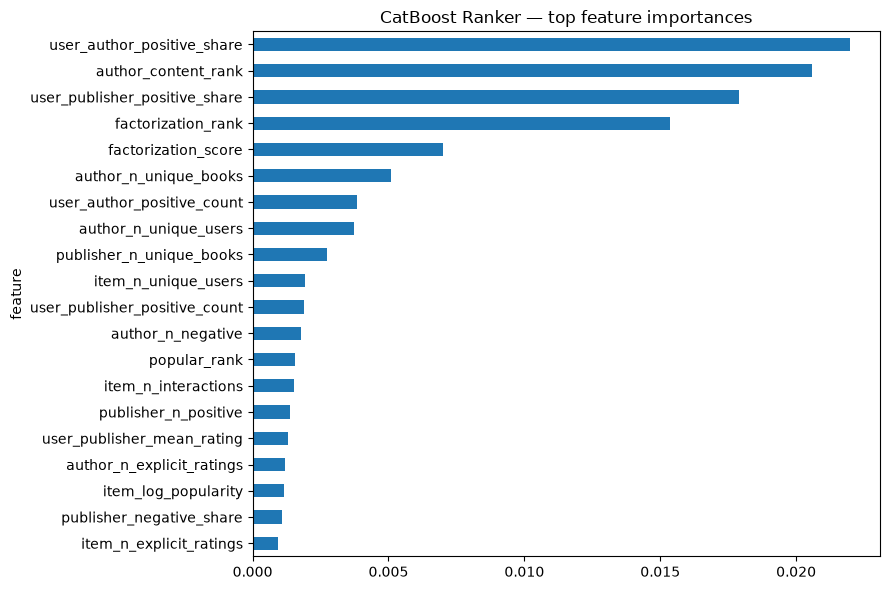

Важность признаков автора и издателя:


,feature,importance
32,user_author_positive_share,0.021986
7,author_content_rank,0.020576
47,user_publisher_positive_share,0.017882
24,author_n_unique_books,0.005095
31,user_author_positive_count,0.003824
25,author_n_unique_users,0.003716
39,publisher_n_unique_books,0.002744
46,user_publisher_positive_count,0.001901
28,author_n_negative,0.001772
38,publisher_n_positive,0.001376


In [25]:
importance = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance": final_ranker.get_feature_importance(all_ranker_pool),
}).sort_values("importance", ascending=False)
display(importance.head(25))
importance.head(20).sort_values("importance").plot(x="feature", y="importance", kind="barh", figsize=(9, 6), legend=False, title="CatBoost Ranker — top feature importances")
plt.tight_layout()
plt.show()

metadata_feature_names = [
    name for name in FEATURE_COLS
    if ("author" in name.lower()) or ("publisher" in name.lower()) or name in {"Book-Author", "Publisher"}
]
metadata_importance = importance[importance["feature"].isin(metadata_feature_names)].copy()
print("Важность признаков автора и издателя:")
display(metadata_importance.sort_values("importance", ascending=False))

In [26]:
eval_candidates = build_candidate_table(eval_source_recs, eval_users, model_train)

eval_feature_tables = fit_feature_tables(model_train, books)
eval_features = build_features(eval_candidates, eval_feature_tables, books, users)

for col in NUMERIC_FEATURES:
    if col not in eval_features.columns:
        eval_features[col] = 0.0
    eval_features[col] = pd.to_numeric(eval_features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0)
for col in CAT_FEATURES:
    eval_features[col] = eval_features[col].fillna("Unknown").astype(str)

eval_features["rank_score"] = final_ranker.predict(eval_features[FEATURE_COLS])
ranker_eval_recs = score_frame_to_recs(eval_features, "rank_score", FINAL_TOP_K)
ranker_metrics = evaluate_recommendations(ranker_eval_recs, test_truth, eval_users, k=FINAL_TOP_K, match_by_work=True)

print("\nМетрики двухэтапной системы на независимой тестовой выборке:")
display(pd.DataFrame([{"model": "CatBoost Ranker", **ranker_metrics}]))


Метрики двухэтапной системы на независимой тестовой выборке:


,model,Recall@20,NDCG@20,HitRate@20,MAP@20
0,CatBoost Ranker,0.079828,0.055789,0.2,0.033164


## Диагностика ранжированной выдачи и Diversity(k)

,k,catalog_coverage,mean_unique_author_ratio,unique_recommended_books
0,5,0.022476,0.46824,6099
1,10,0.038046,0.40284,10324
2,20,0.059368,0.41932,16110
3,50,0.097476,0.49404,26451


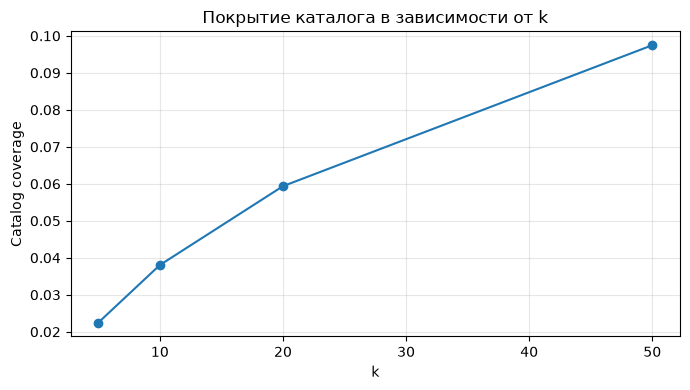

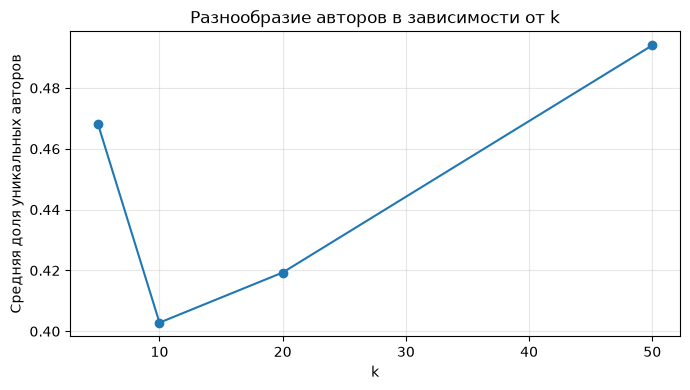

In [27]:
def diversity_report(recommendations: Dict[int, List[Tuple[str, float]]], catalog: pd.DataFrame,
                     user_ids: Iterable[int], k_values=(5, 10, 20, 50)) -> pd.DataFrame:
    author_map = catalog.drop_duplicates("ISBN").set_index("ISBN")["Book-Author"].to_dict()
    rows = []
    catalog_size = max(1, catalog["ISBN"].nunique())
    for k in k_values:
        all_items = set()
        per_user_author_diversity = []
        for uid in user_ids:
            items = [str(x[0]) for x in recommendations.get(int(uid), [])[:k]]
            all_items.update(items)
            authors = [author_map.get(isbn, "Unknown") for isbn in items]
            known_authors = [a for a in authors if a and a != "Unknown"]
            per_user_author_diversity.append(len(set(known_authors)) / max(1, len(items)))
        rows.append({
            "k": k,
            "catalog_coverage": len(all_items) / catalog_size,
            "mean_unique_author_ratio": float(np.mean(per_user_author_diversity)) if per_user_author_diversity else 0.0,
            "unique_recommended_books": len(all_items),
        })
    return pd.DataFrame(rows)

ranked_at_many = score_frame_to_recs(eval_features, "rank_score", max(50, FINAL_TOP_K))
diversity_df = diversity_report(ranked_at_many, books, eval_users)
display(diversity_df)

plt.figure(figsize=(7, 4))
plt.plot(diversity_df["k"], diversity_df["catalog_coverage"], marker="o")
plt.xlabel("k")
plt.ylabel("Catalog coverage")
plt.title("Покрытие каталога в зависимости от k")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(diversity_df["k"], diversity_df["mean_unique_author_ratio"], marker="o")
plt.xlabel("k")
plt.ylabel("Средняя доля уникальных авторов")
plt.title("Разнообразие авторов в зависимости от k")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Обучение на всей выборке

In [28]:
full_models = fit_recommenders(ratings.drop(columns=["_row_id", "is_positive"], errors="ignore"), books)
full_history = ratings.drop(columns=["_row_id", "is_positive"], errors="ignore").copy()
full_seen_map = build_seen_map(full_history)
full_feature_tables = fit_feature_tables(full_history, books)

Обучение генератора популярности...
Обучение ALS...


100%|██████████| 12/12 [00:03<00:00,  3.21it/s]


пользователей — 84,070, книг — 252,852, ненулевых взаимодействий — 937,505
Обучение генератора предпочтений по авторам и издателям...


In [29]:
def rank_candidate_batch(candidates: pd.DataFrame, feature_tables: dict, catalog: pd.DataFrame,
                         user_meta: pd.DataFrame, model: CatBoostRanker,
                         feature_cols: List[str], numeric_cols: List[str], cat_cols: List[str], k: int):
    if candidates.empty:
        return {}
    feat = build_features(candidates, feature_tables, catalog, user_meta)
    for col in feature_cols:
        if col not in feat.columns:
            feat[col] = 0.0 if col not in cat_cols else "Unknown"
    for col in numeric_cols:
        feat[col] = pd.to_numeric(feat[col], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0.0)
    for col in cat_cols:
        feat[col] = feat[col].fillna("Unknown").astype(str)
    feat["rank_score"] = model.predict(feat[feature_cols])
    return score_frame_to_recs(feat, "rank_score", k)


if INFER_ALL_USERS:
    inference_users = np.sort(users["User-ID"].unique())
else:
    inference_users = np.sort(full_history["User-ID"].unique())

output_path = Path("book_recommendations.csv")
if output_path.exists():
    output_path.unlink()

catalog_titles = books.drop_duplicates("ISBN").set_index("ISBN")["Book-Title"].to_dict()

full_seen_map = build_seen_map(full_history)
full_seen_work_map = build_seen_work_map(full_history)

written_rows = 0
for start in tqdm(range(0, len(inference_users), INFERENCE_BATCH_SIZE), desc="Финальная генерация рекомендаций"):
    batch_users = inference_users[start:start + INFERENCE_BATCH_SIZE]
    
    source_recs = generate_source_recommendations(
        full_models, batch_users, full_history, k=TOPK_PER_MODEL, 
        seen_map=full_seen_map, seen_work_map=full_seen_work_map
    )
    
    batch_candidates = build_candidate_table(
        source_recs, batch_users, full_history, 
        seen_map=full_seen_map, seen_work_map=full_seen_work_map
    )
    
    batch_recs = rank_candidate_batch(
        batch_candidates, full_feature_tables, books, users,
        final_ranker, FEATURE_COLS, NUMERIC_FEATURES, CAT_FEATURES, FINAL_TOP_K,
    )

    fallback_raw = full_models["popular"].recommend_many(
        batch_users, full_seen_map, k=min(len(books), TOPK_PER_MODEL * 5)
    )
    
    fallback_map = dedupe_recommendations_by_work(
        fallback_raw, full_seen_map, full_seen_work_map, k=FINAL_TOP_K
    )
    
    rows = []
    for uid in batch_users:
        recs = list(batch_recs.get(int(uid), []))
        used_isbns = {str(isbn) for isbn, _ in recs}
        used_work_keys = {isbn_to_work_key.get(str(isbn), f"isbn::{isbn}") for isbn, _ in recs}
        
        for isbn, score in fallback_map.get(int(uid), []):
            if len(recs) >= FINAL_TOP_K:
                break
            isbn = str(isbn)
            work_key = isbn_to_work_key.get(isbn, f"isbn::{isbn}")
            if isbn not in used_isbns and work_key not in used_work_keys:
                recs.append((isbn, float(score)))
                used_isbns.add(isbn)
                used_work_keys.add(work_key)
                
        rows.append({
            "User-ID": int(uid),
            "Recommended-ISBNs": " ".join(str(isbn) for isbn, _ in recs[:FINAL_TOP_K]),
            "Recommended-Book-Titles": " | ".join(catalog_titles.get(str(isbn), "Unknown") for isbn, _ in recs[:FINAL_TOP_K]),
        })
        
    batch_output = pd.DataFrame(rows)
    batch_output.to_csv(output_path, index=False, mode="w" if start == 0 else "a", header=(start == 0), encoding="utf-8")
    written_rows += len(batch_output)
    
    del source_recs, batch_candidates, batch_recs, batch_output, fallback_raw, fallback_map
    gc.collect()

pd.read_csv(output_path).head()

Финальная генерация рекомендаций: 100%|██████████| 279/279 [21:05<00:00,  4.54s/it]


,User-ID,Recommended-ISBNs,Recommended-Book-Titles
0,1,0971880107 0385504209 0316666343 0804106304 06...,Wild Animus | The Da Vinci Code | The Lovely B...
1,2,0971880107 0192815326 0198607024 0192860925 03...,"Wild Animus | Frankenstein: Or, the Modern Pro..."
2,3,0971880107 0385504209 0316666343 0804106304 06...,Wild Animus | The Da Vinci Code | The Lovely B...
3,4,0971880107 0385504209 0316666343 0804106304 06...,Wild Animus | The Da Vinci Code | The Lovely B...
4,5,0971880107 0385504209 0316666343 0804106304 06...,Wild Animus | The Da Vinci Code | The Lovely B...


In [30]:
final_csv = pd.read_csv("book_recommendations.csv")

final_metric_rows = [
    {"Модель": GENERATOR_NAMES_RU.get(name, str(name)), **evaluate_recommendations(rec_map, test_truth, eval_users, FINAL_TOP_K, match_by_work=True)}
    for name, rec_map in eval_source_recs.items()
]
final_metric_rows.append({"Модель": "Двухэтапная система с CatBoost Ranker", **ranker_metrics})
print(pd.DataFrame(final_metric_rows).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                               Модель  Recall@20  NDCG@20  HitRate@20  MAP@20
                         Популярность     0.0214   0.0148      0.0772  0.0074
                                  ALS     0.0469   0.0299      0.1384  0.0150
    Предпочтения по автору и издателю     0.0598   0.0396      0.1496  0.0233
Двухэтапная система с CatBoost Ranker     0.0798   0.0558      0.2000  0.0332
